<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/%D0%97%D0%B0%D0%BD%D1%8F%D1%82%D1%82%D1%8F_1_%D0%A9%D0%BE_%D1%82%D0%B0%D0%BA%D0%B5_%D0%BC%D0%B0%D1%88%D0%B8%D0%BD%D0%BD%D0%B5_%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D1%96_%D0%BA%D0%BE%D0%BB%D0%B8_%D0%B2%D0%BE%D0%BD%D0%BE_%D0%BF%D0%BE%D1%82%D1%80%D1%96%D0%B1%D0%BD%D0%B5_%D0%B0%D0%BD%D0%B0%D0%BB%D1%96%D1%82%D0%B8%D0%BA%D1%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Заняття 1. Що таке машинне навчання і коли воно потрібне аналітику

**Блок 1. ML-фундамент і бізнес-рамка**

## 1. Правило проти моделі

Аналітик щодня відповідає на запитання «що було?» (звіти, дашборди). Машинне навчання відповідає
на запитання **«що буде?»** або **«до якої групи це належить?»**.

- **Звичайне програмування:** людина пише правило → комп'ютер застосовує його до даних.
  *«Якщо клієнт не заходив 30 днів — він іде»*.
- **Машинне навчання:** людина дає приклади з відповідями → комп'ютер сам знаходить правило.
  *«Ось 10 000 клієнтів, і ми знаємо, хто з них пішов. Знайди закономірність»*.

### Словник, який знадобиться весь курс

| Термін | Що це | Приклад у кав'ярні |
|---|---|---|
| **Об'єкт** (рядок) | одне спостереження | один день роботи |
| **Ознаки**, `X` (features) | те, що відомо заздалегідь | день тижня, температура, акція |
| **Ціль**, `y` (target) | те, що хочемо передбачити | виручка за день |
| **Навчання** (`fit`) | модель шукає зв'язок між `X` та `y` | |
| **Прогноз** (`predict`) | модель дає `y` для нових `X` | виручка на завтра |
| **Тестові дані** | приклади, яких модель не бачила | останні місяці |

## 2. Коли ML справді потрібен

ML виправданий, коли **одночасно** виконано п'ять умов:

1. **Рішення повторюється часто** (тисячі клієнтів, щоденні прогнози), а не раз на рік.
2. **Є історичні дані з відповідями** — ми знаємо, що сталося в минулому.
3. **Правило вручну складне**: факторів багато, вони впливають одночасно.
4. **Помилка допустима**: модель помилятиметься, і бізнес має бути до цього готовим.
5. **Прогноз можна використати**: є людина або система, яка діятиме за результатом.

**ML не потрібен**, якщо відповідь дає SQL-запит («скільки замовлень було вчора?»),
якщо даних кілька десятків рядків, або якщо закон вимагає точного пояснюваного правила.

### Життєвий цикл ML-проєкту і роль аналітика

`бізнес-питання → ML-задача → дані → модель → оцінка → впровадження → моніторинг`

Джун-аналітик найчастіше працює на кроках **«бізнес-питання → дані → оцінка»**: формулює задачу,
готує датасет, будує просту модель-орієнтир і пояснює результат бізнесу.

## 3. Демонстрація: прогноз виручки кав'ярні

Власниця кав'ярні хоче знати виручку на наступний день, щоб планувати закупівлю молока й випічки
та кількість бариста

In [1]:
# Підготовка: бібліотеки та функція завантаження даних (працює в Colab і локально)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
DATA_URL = "https://raw.githubusercontent.com/KsiuTretyakova/ml_for_analys_dta_2026/refs/heads/main/data"  # необов'язково: адреса теки з CSV (наприклад, raw-посилання на GitHub)


def load_csv(name):
    """Читає CSV з поточної теки, з теки data/, з DATA_URL або просить завантажити файл у Colab."""
    for path in (name, os.path.join("data", name)):
        if os.path.exists(path):
            return pd.read_csv(path)
    if DATA_URL:
        return pd.read_csv(DATA_URL.rstrip("/") + "/" + name)
    from google.colab import files
    print(f"Натисніть «Choose files» і виберіть файл {name}")
    files.upload()
    return pd.read_csv(name)

In [2]:
sales = load_csv("coffee_shop_sales.csv")
sales["date"] = pd.to_datetime(sales["date"])
print(sales.shape)
sales.head()

(731, 8)


,date,weekday,is_weekend,is_holiday,temperature_c,rain_mm,promo,sales_uah
0,2024-01-01,Monday,0,1,-0.4,4.6,0,9794
1,2024-01-02,Tuesday,0,0,-5.1,13.1,0,5878
2,2024-01-03,Wednesday,0,0,1.1,20.2,0,8599
3,2024-01-04,Thursday,0,0,1.7,0.0,0,8859
4,2024-01-05,Friday,0,0,-8.5,9.7,1,10154


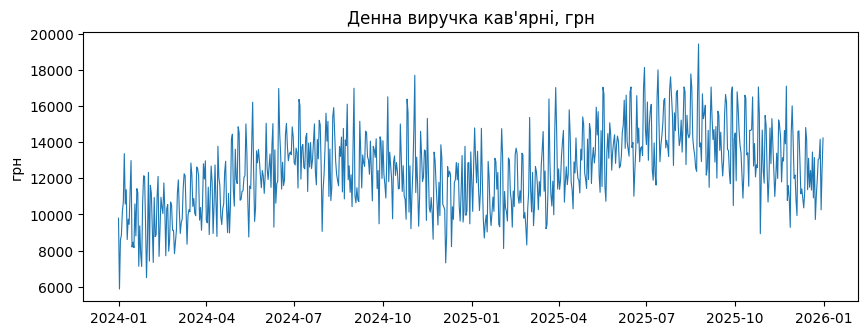

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sales["date"], sales["sales_uah"], lw=0.8)
ax.set_title("Денна виручка кав'ярні, грн")
ax.set_ylabel("грн")
plt.show()

Видно сезонність (влітку більше), коливання по днях і загальне зростання.

### Крок 1. Розділяємо минуле і «майбутнє»

Модель вчиться на 2024 році, а перевіряємо її на 2025-му — так, ніби 2025 ще не настав.
Це головне правило ML: **оцінювати модель лише на даних, яких вона не бачила.**

In [4]:
train = sales[sales["date"] < "2025-01-01"]
test = sales[sales["date"] >= "2025-01-01"]
print("Навчальні дні:", len(train), "| Тестові дні:", len(test))

Навчальні дні: 366 | Тестові дні: 365


### Крок 2. Найпростіше правило (baseline)

Перш ніж будувати модель, завжди рахуємо, як добре працює **найпростіший спосіб**.
Правило: «виручка = середня виручка за цей день тижня у 2024 році».

Якість вимірюємо **середньою абсолютною помилкою (MAE)**: на скільки гривень у середньому
помиляється прогноз. Менше — краще.

In [5]:
from sklearn.metrics import mean_absolute_error

rule = train.groupby("weekday")["sales_uah"].mean()
pred_rule = test["weekday"].map(rule)
mae_rule = mean_absolute_error(test["sales_uah"], pred_rule)
print(f"Правило «середнє за днем тижня»: помилка в середньому {mae_rule:,.0f} грн на день")

Правило «середнє за днем тижня»: помилка в середньому 1,831 грн на день


### Крок 3. Перша модель — лінійна регресія

Робота з будь-якою моделлю в `scikit-learn` — це завжди три кроки:

```python
model = SomeModel()       # 1. створити
model.fit(X_train, y_train)   # 2. навчити на прикладах
model.predict(X_test)     # 3. зробити прогноз
```

In [6]:
from sklearn.linear_model import LinearRegression

features = ["is_weekend", "is_holiday", "temperature_c", "rain_mm", "promo"]
X_train, y_train = train[features], train["sales_uah"]
X_test, y_test = test[features], test["sales_uah"]

model = LinearRegression()
model.fit(X_train, y_train)
pred_model = model.predict(X_test)

mae_model = mean_absolute_error(y_test, pred_model)
print(f"Лінійна регресія: помилка в середньому {mae_model:,.0f} грн на день")
print(f"Виграш порівняно з правилом: {mae_rule - mae_model:,.0f} грн на день")

Лінійна регресія: помилка в середньому 1,587 грн на день
Виграш порівняно з правилом: 244 грн на день


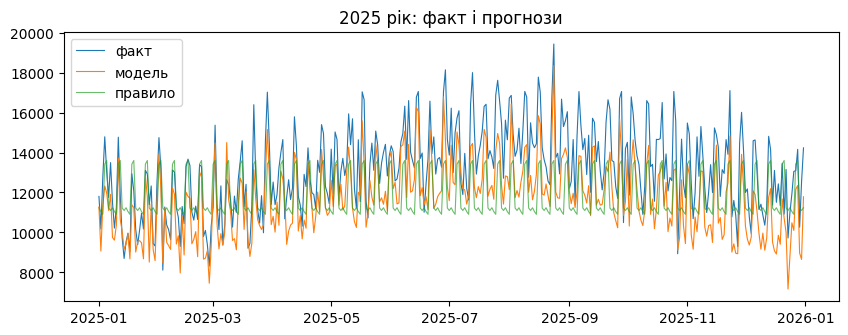

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(test["date"], y_test, lw=0.8, label="факт")
ax.plot(test["date"], pred_model, lw=0.8, label="модель")
ax.plot(test["date"], pred_rule, lw=0.8, label="правило", alpha=0.7)
ax.set_title("2025 рік: факт і прогнози")
ax.legend()
plt.show()

### Що показує результат

- Модель врахувала **погоду і акції**, яких правило не бачить, тому помиляється менше.
- Подивіться на графік: у 2025 році прогноз моделі **здебільшого нижчий за факт**. Кав'ярня
  росте, а модель про це не знає: серед ознак немає «часу». Це типова ситуація, з якою ми
  працюватимемо на заняттях про ознаки й валідацію.
- Для бізнесу результат звучить так: *«Прогноз помиляється в середньому на N грн на день;
  це на M грн точніше, ніж планування за днем тижня»*. Не «R² = 0.7», а гроші й рішення.

In [8]:
# Як модель «бачить» вплив кожної ознаки: коефіцієнт = зміна виручки, якщо ознака зросте на 1
pd.Series(model.coef_, index=features).round(0)

,0
is_weekend,2563.0
is_holiday,2158.0
temperature_c,122.0
rain_mm,-81.0
promo,1851.0


Акція додає приблизно стільки гривень, скільки показує коефіцієнт `promo`, вихідний день —
коефіцієнт `is_weekend`. Такі числа зрозумілі бізнесу без формул. Детально про це — на занятті 6.

---
## 4. Практика

### Завдання 1. Потрібен ML чи ні?

Для кожної ситуації вкажіть `"ML"` або `"не ML"` і коротко поясніть, чому (за п'ятьма умовами з розділу 2).

1. Рішення повторюється часто (тисячі клієнтів, щоденні прогнози), а не раз на рік.
2. Є історичні дані з відповідями — ми знаємо, що сталося в минулому.
3. Правило вручну складне: факторів багато, вони впливають одночасно.
4. Помилка допустима: модель помилятиметься, і бізнес має бути до цього готовим.
5. Прогноз можна використати: є людина або система, яка діятиме за результатом.

In [9]:
    # 1. Скільки нових клієнтів зареєструвалося минулого місяця?
    # 2. Які з 50 000 клієнтів банку, ймовірно, не повернуть кредит?
    # 3. Яку ціну поставити на новий унікальний будинок (один на рік)?
    # 4. Скільки бариста вивести на зміну завтра в кожній із 40 кав'ярень мережі?
    # 5. Розсилати лист усім клієнтам, які нічого не купували 90 днів?
    # 6. Які листи в службу підтримки - скарги, а які - запитання (2000 листів на день)?
# Ваш код тут

1. Not ML - це факт з минулого
2. ML - даних багато, є історія (якщо записів даних одиниці - not ML)
3. Not ML
4. ML
5. Not ML
6. ML

### Завдання 2. Дані прокату велосипедів

Мережа прокату хоче прогнозувати кількість прокатів на день (`rentals`), щоб планувати, скільки
велосипедів вивести на станції. Завантажте `bike_rentals_daily.csv`, перетворіть `date` на дату,
виведіть розмір таблиці й побудуйте графік `rentals` у часі. Що ви бачите?

In [10]:
bikes = load_csv("bike_rentals_daily.csv")
# Видно сезонність (літо - пік) і зростання мережі з року в рік.
# Ваш код тут

### Завдання 3. Розділення і просте правило

1. Навчальні дані — до `2025-01-01`, тестові — з `2025-01-01`.
2. Правило-орієнтир: прогноз = середня кількість прокатів у навчальних даних окремо для
   вихідних і будніх днів (`is_weekend`).
3. Порахуйте MAE правила на тесті.

In [14]:
# 1. Розділяємо дані на навчальні та тестові
train = bikes[bikes["date"] < "2025-01-01"]
test = bikes[bikes["date"] >= "2025-01-01"]

# 2. Перевіряємо розмір кожної таблиці
print("Навчальні дані:", train.shape)
print("Тестові дані:", test.shape)

# 3. Обчислюємо середню кількість прокатів для буднів і вихідних
rule = train.groupby("is_weekend")["rentals"].mean()

print(rule)

# 4. Прогнозуємо кількість прокатів на тестових даних
pred_rule = test["is_weekend"].map(rule)

# Переглядаємо перші 5 прогнозів
print(pred_rule.head())

Навчальні дані: (731, 7)
Тестові дані: (181, 7)
is_weekend
0    1756.057471
1    2177.105263
Name: rentals, dtype: float64
731    1756.057471
732    1756.057471
733    1756.057471
734    2177.105263
735    2177.105263
Name: is_weekend, dtype: float64


### Завдання 4. Перша модель

Навчіть `LinearRegression` на ознаках `temperature_c`, `humidity_pct`, `wind_kmh`, `is_weekend`,
`is_holiday`. Порахуйте MAE на тесті й порівняйте з правилом.

In [17]:
# 1. Імпортуємо LinearRegression
from sklearn.linear_model import LinearRegression

# 2. Створюємо модель
model = LinearRegression()

# 3. Навчаємо модель
model.fit(X_train, y_train)

# 4. Робимо прогноз на тестових даних
pred_model = model.predict(X_test)

# 5. Рахуємо MAE моделі
mae_model = mean_absolute_error(y_test, pred_model)

# 6. Порівнюємо MAE моделі з MAE простого правила
print("MAE правила:", round(mae_rule, 2))
print("MAE моделі:", round(mae_model, 2))

MAE правила: 1830.99
MAE моделі: 524.14


Модель LinearRegression показала кращий результат порівняно з простим правилом прогнозування. MAE зменшився з 1830.99 до 524.14, тобто приблизно на 71,4%. Це означає, що використання температури, вологості, швидкості вітру, вихідних і свят дозволило отримати точніший прогноз кількості прокатів велосипедів.

### Завдання 5. Графік і висновок для менеджера

1. Побудуйте на одному графіку факт і прогноз моделі для тестового періоду.
2. Чи є період, де модель систематично помиляється в один бік? Чому це може бути?
   *Підказка: подивіться, як змінювалась кількість прокатів з року в рік.*
3. Напишіть 2–3 речення для менеджера мережі: наскільки модель корисна, у чому її обмеження.

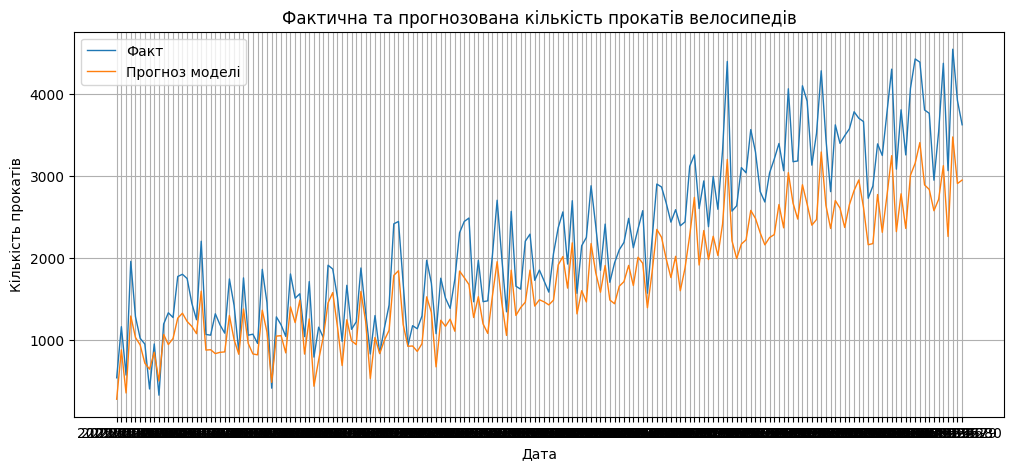

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Фактична кількість прокатів
plt.plot(test["date"], y_test, label="Факт", linewidth=1)

# Прогноз моделі
plt.plot(test["date"], pred_model, label="Прогноз моделі", linewidth=1)

plt.title("Фактична та прогнозована кількість прокатів велосипедів")
plt.xlabel("Дата")
plt.ylabel("Кількість прокатів")
plt.legend()
plt.grid(True)
plt.show()

Модель LinearRegression показала кращу точність, ніж просте правило: MAE становить 524.14 проти 1830.99. Вона враховує погодні умови, вихідні та свята, але систематично занижує прогноз, оскільки не враховує зростання мережі та попиту з часом. Для покращення прогнозів потрібно регулярно перенавчати модель або додати ознаку, яка враховує часовий тренд розвитку мережі.

---
## Підсумок

- ML знаходить правило з прикладів: **ознаки `X` → ціль `y`**.
- Перед моделлю — **просте правило-орієнтир (baseline)**. Модель цінна, лише якщо краща за нього.
- Модель оцінюємо **на даних, яких вона не бачила**, і результат перекладаємо в мову бізнесу.
- Модель не знає того, чого немає в ознаках (наприклад, зростання бізнесу).